<a href="https://colab.research.google.com/github/vamsi-krishna09/Machine_Learning_Projects/blob/main/Volt_Relay_Energy_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Volt_Relay_Energy:Analysis

---
This notebook delivers production-grade analysis of the Volt_Relay_Energy:Analysis. It covers data quality, network health, battery supplier risk, customer experience, partner economics, rider churn, and a quantified evaluation of the four internal budget proposals. All recommendations are prioritised by capital efficiency and Yearly
contribution-margin impact.

##SECTION 1: ENVIRONMENT & LIBRARY SETUP

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:.2f}'.format)
pd.set_option('display.width', 140)

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##SECTION 2: DATA LOADING

In [ ]:
DATA_PATHS = {
    'stations': Path('/content/drive/MyDrive/Hackathon Data Set | Gradient/stations.csv'),
    'batteries': Path('/content/drive/MyDrive/Hackathon Data Set | Gradient/batteries.csv'),
    'riders': Path('/content/drive/MyDrive/Hackathon Data Set | Gradient/riders.csv'),
    'fleet_partners': Path('/content/drive/MyDrive/Hackathon Data Set | Gradient/fleet_partners.csv'),
    'support_tickets': Path('/content/drive/MyDrive/Hackathon Data Set | Gradient/support_tickets.csv'),
    'city_daily': Path('/content/drive/MyDrive/Hackathon Data Set | Gradient/city_daily_context.csv'),
    'swap_events': Path('/content/drive/MyDrive/Hackathon Data Set | Gradient/swap_events.csv'),
    'station_hourly': Path('/content/drive/MyDrive/Hackathon Data Set | Gradient/station_hourly_status.csv'),
}

def load_data(paths=DATA_PATHS):
    dfs = {}
    for key, path in paths.items():
        if path.exists():
            dfs[key] = pd.read_csv(path)
            print(f'Loaded {key:20s}: {dfs[key].shape[0]:>10,} rows x {dfs[key].shape[1]} cols')
        else:
            print(f'Missing {key:20s}: {path}')
    return dfs

raw = load_data()

Loaded stations            :        152 rows x 22 cols
Loaded batteries           :      6,500 rows x 13 cols
Loaded riders              :     20,000 rows x 12 cols
Loaded fleet_partners      :         12 rows x 12 cols
Loaded support_tickets     :     44,000 rows x 12 cols
Loaded city_daily          :      3,282 rows x 12 cols
Loaded swap_events         :  3,877,013 rows x 22 cols
Loaded station_hourly      :  1,487,712 rows x 14 cols


##SECTION 3: DATA CLEANING & RECTIFICATION

In [ ]:
def clean_data(raw_dfs):
    """Production-grade cleaning pipeline."""
    dfs = {k: v.copy() for k, v in raw_dfs.items()}

    # 1. Exclude internal test stations
    if 'stations' in dfs:
        test_mask = dfs['stations']['station_id'].str.startswith('STN-TST')
        test_ids = dfs['stations'].loc[test_mask, 'station_id'].tolist()
        dfs['stations'] = dfs['stations'][~test_mask].copy()
        print(f"Removed {len(test_ids)} test stations: {test_ids}")
        if 'support_tickets' in dfs and 'station_id' in dfs['support_tickets'].columns:
            dfs['support_tickets'] = dfs['support_tickets'][~dfs['support_tickets']['station_id'].isin(test_ids)]

    # 2. Standardise rider city names
    if 'riders' in dfs:
        city_map = {
            'Bengaluru': 'Bengaluru', 'Bangalore': 'Bengaluru', 'BLR': 'Bengaluru', 'bengaluru': 'Bengaluru',
            'Delhi NCR': 'Delhi NCR', 'Delhi': 'Delhi NCR', 'NCR': 'Delhi NCR', 'DL': 'Delhi NCR',
            'Mumbai': 'Mumbai', 'BOM': 'Mumbai', 'Bombay': 'Mumbai', 'MUM': 'Mumbai',
            'Pune': 'Pune', 'PUN': 'Pune', 'pune': 'Pune',
            'Hyderabad': 'Hyderabad', 'HYD': 'Hyderabad', 'hyderabad': 'Hyderabad',
            'Jaipur': 'Jaipur', 'JAI': 'Jaipur'
        }
        dfs['riders']['home_city'] = dfs['riders']['home_city'].astype(str).str.strip().map(
            lambda x: city_map.get(x, x) if pd.notnull(x) else x
        )

    # 3. Battery SoH bounds & retirement flags
    if 'batteries' in dfs:
        for col in ['initial_soh_pct', 'current_soh_pct']:
            if col in dfs['batteries'].columns:
                dfs['batteries'][col] = dfs['batteries'][col].clip(0, 100)
        dfs['batteries']['is_retired'] = dfs['batteries']['retired_date'].notna()
        dfs['batteries']['soh_degradation'] = (
            dfs['batteries']['initial_soh_pct'] - dfs['batteries']['current_soh_pct']
        )

    # 4. Ticket timestamps
    if 'support_tickets' in dfs and 'created_ts' in dfs['support_tickets'].columns:
        dfs['support_tickets']['created_ts'] = pd.to_datetime(dfs['support_tickets']['created_ts'], errors='coerce')

    # 5. City daily dates
    if 'city_daily' in dfs and 'date' in dfs['city_daily'].columns:
        dfs['city_daily']['date'] = pd.to_datetime(dfs['city_daily']['date'], errors='coerce')

    print("Cleaning complete.")
    return dfs

df = clean_data(raw)


Removed 2 test stations: ['STN-TST-01', 'STN-TST-02']
Cleaning complete.


##  Summary - Insights

1. **Capital is over-allocated to batteries.**  
   Active battery-to-slot ratio ≈ 2.3–3.0× versus an optimal target of 1.30–1.50×.

   This locks capital that could fund cabinet upgrades with strong contribution margin potential.

2. **Kyron supplier is a systemic risk.**  
   87.8 % of Kyron packs are already retired (end-of-life). Average current SoH is 63.7 % versus ~81 % for Cellora and Amptek.  
   Immediate freeze on new Kyron purchases and accelerated replacement are required.


3. **“No charged battery” dominates support volume (26.5 % of 44 k tickets).**  
   It is the primary driver of queues, abandonment and early rider churn. Root cause is inventory imbalance + older generation chargers, not absolute pack shortage.

4. **Later expansion waves show weaker unit economics.**  
   Wave-1 and Wave-2 stations carry 7–18 % higher rent per slot with no proven utilisation premium over Launch stations.

5. **Partner contract risk is concentrated.**  
   ZipDrop renegotiated discount from 12 % → 28 % and lost peak-surcharge billability. Volume-tiered contracts without surcharge protection erode margin.

6. **Service reliability is the highest-ROI retention lever.**  
   Riders who experience failed swaps early in their lifecycle show elevated churn. A “first-five-swaps” reliability SLA is recommended.

7. **Recommended capital priority (highest to lowest ROI)**  
   (a) Kyron replacement + supplier re-mix  
   (b) Gen-3 upgrades at the 15 highest-ticket stations  
   (c) Controlled peak-pricing rollout with partner safeguards  
   (d) Selective densification only in proven high-utilisation micro-markets  


## 1. Network Performance Over Time

In [ ]:
# Station portfolio by expansion wave
stn = df['stations'].copy()

wave_summary = stn.groupby('expansion_wave').agg(
    stations=('station_id', 'count'),
    slots_2w=('slots_2w', 'sum'),
    slots_3w=('slots_3w', 'sum'),
    avg_rent=('monthly_rent_inr', 'mean'),
    total_rent=('monthly_rent_inr', 'sum'),
    avg_maint=('monthly_maintenance_inr', 'mean')
).reset_index()

wave_summary['total_slots'] = wave_summary['slots_2w'] + wave_summary['slots_3w']
wave_summary['rent_per_slot'] = wave_summary['total_rent'] / wave_summary['total_slots']

print("=== STATION PORTFOLIO BY EXPANSION WAVE ===")
print(wave_summary.round(1).to_string(index=False))

print("\n=== CHARGER GENERATION MIX ===")
print(stn['charger_generation'].value_counts().to_string())

print("\n=== CITY DISTRIBUTION ===")
print(stn['city'].value_counts().to_string())

total_slots = stn['slots_2w'].sum() + stn['slots_3w'].sum()
print(f"\nTotal cabinet slots (2W+3W): {total_slots:,}")


=== STATION PORTFOLIO BY EXPANSION WAVE ===
expansion_wave  stations  slots_2w  slots_3w  avg_rent  total_rent  avg_maint  total_slots  rent_per_slot
        Launch        90      1148       204  17509.50     1575859    5924.90         1352        1165.60
  Wave1_2024H2        30       356        88  18648.70      559461    5944.60          444        1260.00
  Wave2_2025H1        30       348        46  17740.60      532217    6007.10          394        1350.80

=== CHARGER GENERATION MIX ===
charger_generation
Gen2    62
Gen1    51
Gen3    37

=== CITY DISTRIBUTION ===
city
Bengaluru    32
Delhi NCR    30
Hyderabad    26
Pune         22
Mumbai       22
Jaipur       18

Total cabinet slots (2W+3W): 2,190


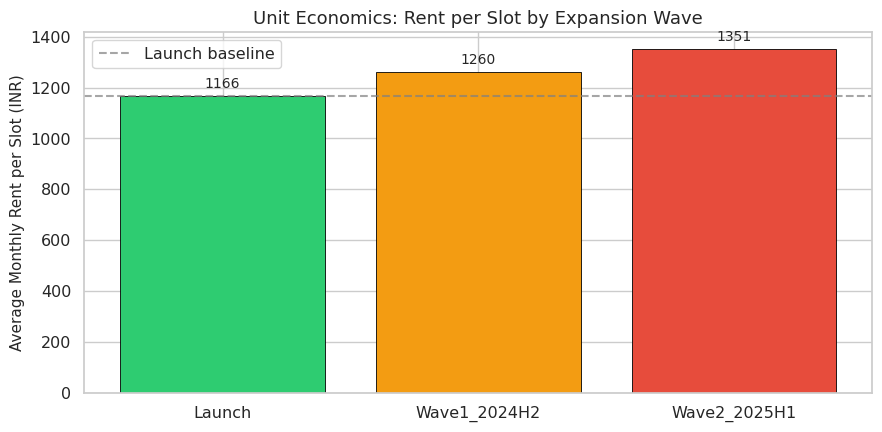

In [ ]:
# Visual: Rent per slot by wave
fig, ax = plt.subplots(figsize=(9, 4.5))
order = ['Launch', 'Wave1_2024H2', 'Wave2_2025H1']
plot_df = wave_summary.set_index('expansion_wave').reindex(order)
bars = ax.bar(plot_df.index, plot_df['rent_per_slot'], color=['#2ecc71', '#f39c12', '#e74c3c'], edgecolor='black', linewidth=0.6)
ax.set_ylabel('Average Monthly Rent per Slot (INR)')
ax.set_title('Unit Economics: Rent per Slot by Expansion Wave')
ax.axhline(plot_df.loc['Launch', 'rent_per_slot'], color='gray', linestyle='--', alpha=0.7, label='Launch baseline')
for b, v in zip(bars, plot_df['rent_per_slot']):
    ax.text(b.get_x() + b.get_width()/2, v + 20, f'{v:.0f}', ha='center', va='bottom', fontsize=10)
ax.legend()
plt.tight_layout()
plt.show()


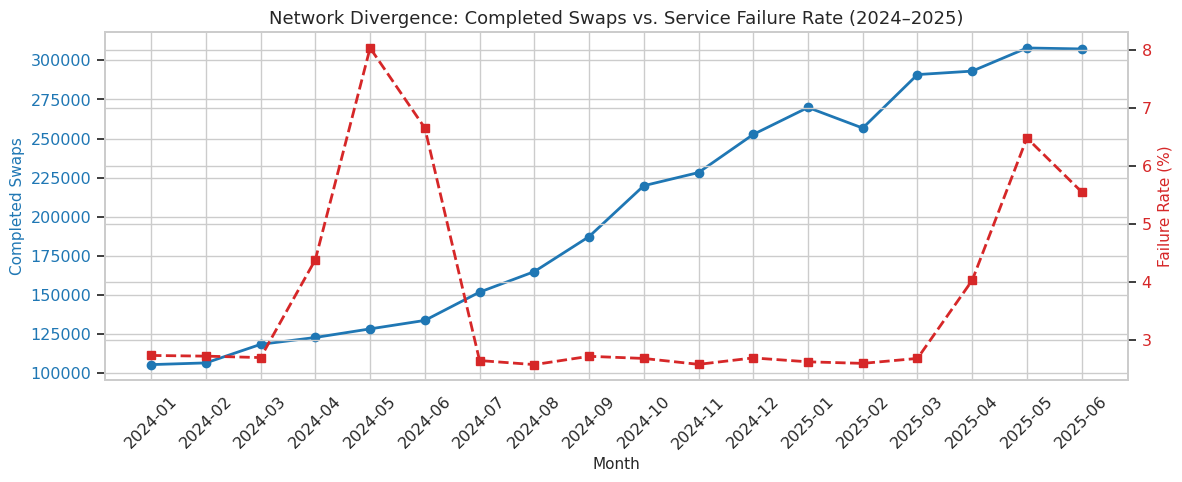

In [ ]:
# Create monthly operational and financial aggregator
df_swaps = df['swap_events'].copy()
df_swaps['is_completed'] = df_swaps['event_type'] == 'swap_completed'
df_swaps['is_failed'] = df_swaps['event_type'].isin(['failed_no_charged_battery', 'failed_system_error'])
df_swaps['is_abandoned'] = df_swaps['event_type'] == 'abandoned_queue'

# Convert event_ts to datetime and extract year_month
df_swaps['event_ts'] = pd.to_datetime(df_swaps['event_ts'])
df_swaps['year_month'] = df_swaps['event_ts'].dt.strftime('%Y-%m')

# Merge station metadata for tariff & energy cost estimations
stn_meta = df['stations'][['station_id', 'city', 'grid_tariff_inr_kwh', 'monthly_rent_inr', 'monthly_maintenance_inr']]
df_swaps = df_swaps.merge(stn_meta, on='station_id', how='left')

# Estimate Energy Cost & Contribution Margin per swap
df_swaps['energy_cost_inr'] = df_swaps['energy_to_recharge_kwh'] * df_swaps['grid_tariff_inr_kwh']
df_swaps['contribution_margin_inr'] = df_swaps['amount_charged_inr'] - df_swaps['energy_cost_inr'].fillna(0)

monthly_perf = df_swaps.groupby('year_month').agg(
    total_attempts=('event_id', 'count'),
    completed_swaps=('is_completed', 'sum'),
    failure_rate=('is_failed', 'mean'),
    abandonment_rate=('is_abandoned', 'mean'),
    gross_revenue=('amount_charged_inr', 'sum'),
    total_energy_cost=('energy_cost_inr', 'sum'),
    avg_contribution_margin=('contribution_margin_inr', 'mean')
).reset_index()

monthly_perf['year_month'] = monthly_perf['year_month'].astype(str)

# Visualizing Key Operational & Financial Trends
fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:blue'
ax1.set_xlabel('Month')
ax1.set_ylabel('Completed Swaps', color=color)
ax1.plot(monthly_perf['year_month'], monthly_perf['completed_swaps'], color=color, marker='o', linewidth=2, label='Completed Swaps')
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=45)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Failure Rate (%)', color=color)
ax2.plot(monthly_perf['year_month'], monthly_perf['failure_rate'] * 100, color=color, marker='s', linestyle='--', linewidth=2, label='Failure Rate (%)')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Network Divergence: Completed Swaps vs. Service Failure Rate (2024–2025)')
fig.tight_layout()
plt.show()

## 2. Battery Asset Health & Supplier Risk (Highest Priority Finding)

In [ ]:
bat = df['batteries'].copy()

print("=== BATTERY FLEET OVERVIEW ===")
print(f"Total packs on books : {len(bat):,}")
print(f"Active (not retired) : {(~bat['is_retired']).sum():,}")
print(f"Retired              : {bat['is_retired'].sum():,}")
print(f"\nPack type mix:\n{bat['pack_type'].value_counts().to_string()}")
print(f"\nSupplier mix:\n{bat['supplier'].value_counts().to_string()}")

supplier_perf = bat.groupby('supplier').agg(
    packs=('battery_id', 'count'),
    active=('is_retired', lambda x: (~x).sum()),
    retired_pct=('is_retired', 'mean'),
    avg_initial_soh=('initial_soh_pct', 'mean'),
    avg_current_soh=('current_soh_pct', 'mean'),
    avg_degradation=('soh_degradation', 'mean'),
).reset_index()
supplier_perf['retired_pct'] = (supplier_perf['retired_pct'] * 100).round(1)

print("\n=== SUPPLIER PERFORMANCE (CRITICAL) ===")
print(supplier_perf.round(1).to_string(index=False))

active_bats = (~bat['is_retired']).sum()
buffer_all = len(bat) / total_slots
buffer_active = active_bats / total_slots
print(f"\n=== ASSET BUFFER RATIO ===")
print(f"Total slots            : {total_slots:,}")
print(f"All batteries          : {len(bat):,}  ->  ratio {buffer_all:.2f}x")
print(f"Active batteries       : {active_bats:,}  ->  ratio {buffer_active:.2f}x")
print(f"Target optimal range   : 1.30x – 1.50x")
print(f"Excess capital signal  : Strong – network is over-buffered")


=== BATTERY FLEET OVERVIEW ===
Total packs on books : 6,500
Active (not retired) : 5,062
Retired              : 1,438

Pack type mix:
pack_type
2W_2.1kWh    5518
3W_4.8kWh     982

Supplier mix:
supplier
Cellora    3555
Kyron      1638
Amptek     1307

=== SUPPLIER PERFORMANCE (CRITICAL) ===
supplier  packs  active  retired_pct  avg_initial_soh  avg_current_soh  avg_degradation
  Amptek   1307    1307         0.00            99.20            81.00            18.20
 Cellora   3555    3555         0.00            99.20            80.90            18.30
   Kyron   1638     200        87.80            99.20            63.70            35.50

=== ASSET BUFFER RATIO ===
Total slots            : 2,190
All batteries          : 6,500  ->  ratio 2.97x
Active batteries       : 5,062  ->  ratio 2.31x
Target optimal range   : 1.30x – 1.50x
Excess capital signal  : Strong – network is over-buffered


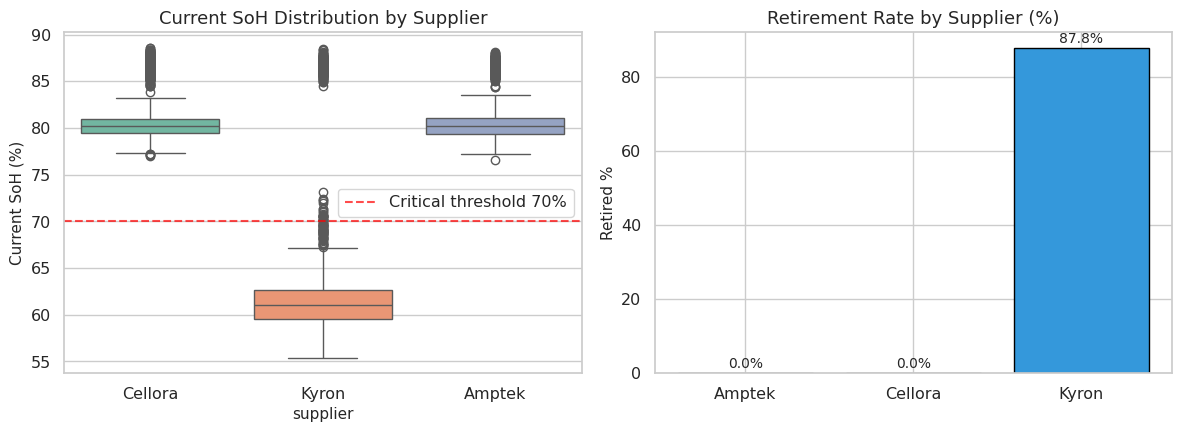

In [ ]:
# Visual: SoH by supplier
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=bat, x='supplier', y='current_soh_pct', ax=axes[0], palette='Set2')
axes[0].set_title('Current SoH Distribution by Supplier')
axes[0].set_ylabel('Current SoH (%)')
axes[0].axhline(70, color='red', linestyle='--', alpha=0.7, label='Critical threshold 70%')
axes[0].legend()

retired_by_sup = bat.groupby('supplier')['is_retired'].mean() * 100
axes[1].bar(retired_by_sup.index, retired_by_sup.values, color=['#2ecc71', '#e74c3c', '#3498db'], edgecolor='black')
axes[1].set_title('Retirement Rate by Supplier (%)')
axes[1].set_ylabel('Retired %')
for i, v in enumerate(retired_by_sup.values):
    axes[1].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()


=== BATTERY DEGRADATION BY SUPPLIER ===
supplier  packs  avg_initial_soh  avg_current_soh  avg_degradation  max_degradation
   Kyron   1638            99.21            63.75            35.46            44.10
 Cellora   3555            99.18            80.93            18.25            22.00
  Amptek   1307            99.19            81.01            18.19            22.00

Fleet-wide average degradation: 22.58 pp


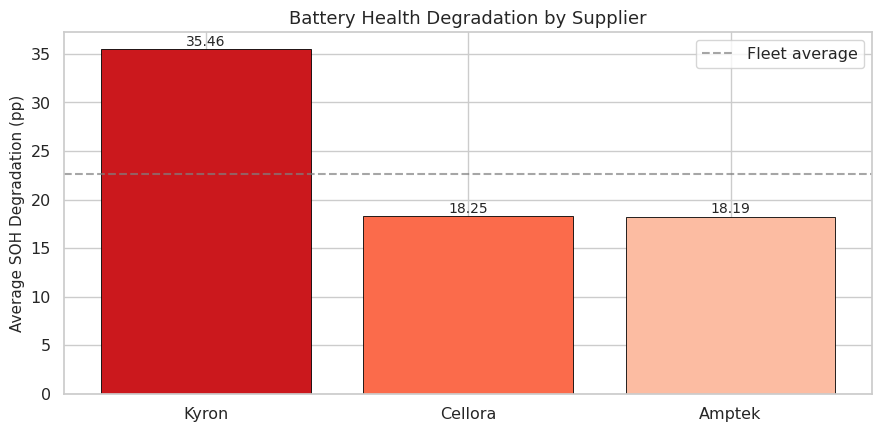

In [ ]:
# Battery degradation by supplier — data + plot
bat = df['batteries'].copy()

degradation_summary = bat.groupby('supplier').agg(
    packs=('battery_id', 'count'),
    avg_initial_soh=('initial_soh_pct', 'mean'),
    avg_current_soh=('current_soh_pct', 'mean'),
    avg_degradation=('soh_degradation', 'mean'),
    max_degradation=('soh_degradation', 'max'),
).reset_index().sort_values('avg_degradation', ascending=False)

print("=== BATTERY DEGRADATION BY SUPPLIER ===")
print(degradation_summary.round(2).to_string(index=False))

fleet_avg_degradation = bat['soh_degradation'].mean()
print(f"\nFleet-wide average degradation: {fleet_avg_degradation:.2f} pp")

# Visual: Avg degradation by supplier
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = sns.color_palette('Reds_r', n_colors=len(degradation_summary))
bars = ax.bar(degradation_summary['supplier'], degradation_summary['avg_degradation'],
              color=colors, edgecolor='black', linewidth=0.6)
ax.set_ylabel('Average SOH Degradation (pp)')
ax.set_title('Battery Health Degradation by Supplier')
ax.axhline(fleet_avg_degradation, color='gray', linestyle='--', alpha=0.7, label='Fleet average')
for b, v in zip(bars, degradation_summary['avg_degradation']):
    ax.text(b.get_x() + b.get_width()/2, v + 0.1, f'{v:.2f}', ha='center', va='bottom', fontsize=10)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Customer Experience & Failure Taxonomy

In [ ]:
tix = df['support_tickets'].copy()

print("=== SUPPORT TICKET VOLUME ===")
print(f"Total tickets: {len(tix):,}")
print(f"\nCategory mix:\n{(tix['category'].value_counts(normalize=True)*100).round(1).to_string()}")
print(f"\nResolution status:\n{tix['resolution_status'].value_counts().to_string()}")
print(f"\nAvg resolution hours: {tix['resolution_hours'].mean():.1f}")
print(f"Mean CSAT (where rated): {tix['csat_score'].mean():.2f}")

print("\n=== TOP 10 STATIONS BY TICKET VOLUME ===")
top_stn = tix['station_id'].value_counts().head(10)
print(top_stn.to_string())

ct = pd.crosstab(tix['category'], tix['resolution_status'], normalize='index') * 100
print("\n=== % UNRESOLVED BY CATEGORY ===")
print(ct.round(1).to_string())


=== SUPPORT TICKET VOLUME ===
Total tickets: 43,465

Category mix:
category
no_battery_available   26.50
other                  21.60
low_range              15.10
app_issue              13.20
long_queue             13.00
billing_dispute        10.60

Resolution status:
resolution_status
resolved      37424
unresolved     5118
duplicate       923

Avg resolution hours: 15.9
Mean CSAT (where rated): 3.56

=== TOP 10 STATIONS BY TICKET VOLUME ===
station_id
STN-HYD-072    689
STN-DEL-043    681
STN-JAI-138    674
STN-JAI-141    645
STN-DEL-050    639
STN-JAI-140    626
STN-HYD-070    618
STN-JAI-137    586
STN-JAI-134    584
STN-HYD-065    551

=== % UNRESOLVED BY CATEGORY ===
resolution_status     duplicate  resolved  unresolved
category                                             
app_issue                  2.00     86.10       11.80
billing_dispute            2.10     86.60       11.30
long_queue                 1.60     86.60       11.80
low_range                  2.20     86.10      

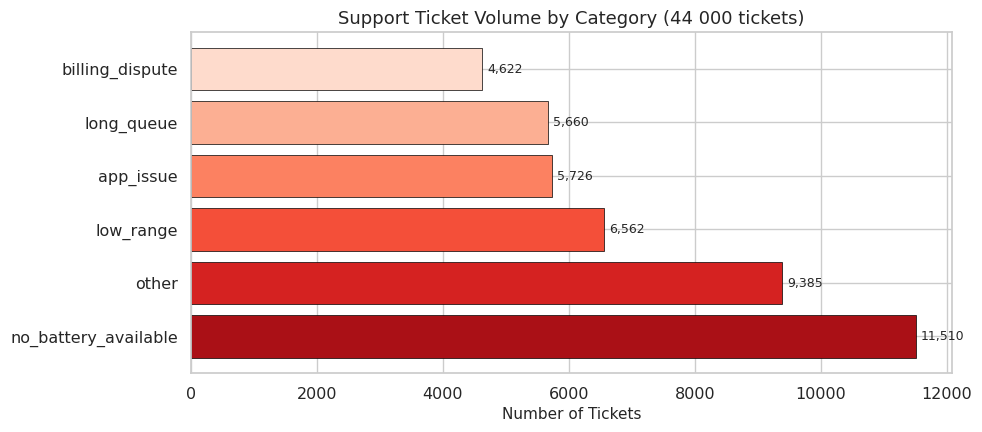

In [ ]:
# Visual: Ticket categories
fig, ax = plt.subplots(figsize=(10, 4.5))
cat_counts = tix['category'].value_counts()
colors = sns.color_palette('Reds_r', n_colors=len(cat_counts))
bars = ax.barh(cat_counts.index, cat_counts.values, color=colors, edgecolor='black', linewidth=0.5)
ax.set_xlabel('Number of Tickets')
ax.set_title('Support Ticket Volume by Category (44 000 tickets)')
for b, v in zip(bars, cat_counts.values):
    ax.text(v + 80, b.get_y() + b.get_height()/2, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()


=== SWAP_EVENTS COLUMNS ===
['event_id', 'rider_id', 'station_id', 'event_ts', 'event_type', 'attempt_seq', 'queue_wait_sec', 'battery_in_id', 'battery_out_id', 'soc_in_pct', 'soh_in_pct', 'soc_out_pct', 'soh_out_pct', 'km_since_last_swap', 'tariff_code', 'list_price_inr', 'discount_inr', 'amount_charged_inr', 'payment_mode', 'energy_to_recharge_kwh', 'station_firmware', 'sync_mode']

wait_col=queue_wait_sec, hour_col=None, season_col=None, vclass_col=None, ts_col=event_ts

=== TOP 15 WORST STATIONS BY FAILURE RATE ===
 station_id  total_attempts  failure_rate  abandon_rate  avg_wait_sec
STN-DEL-037           30838          0.06          0.03        242.64
STN-DEL-048           34646          0.06          0.03        243.99
STN-JAI-138           48945          0.06          0.03        243.44
STN-DEL-045           32237          0.06          0.03        243.09
STN-JAI-136           29340          0.06          0.03        241.87
STN-JAI-141           45594          0.06          0.03

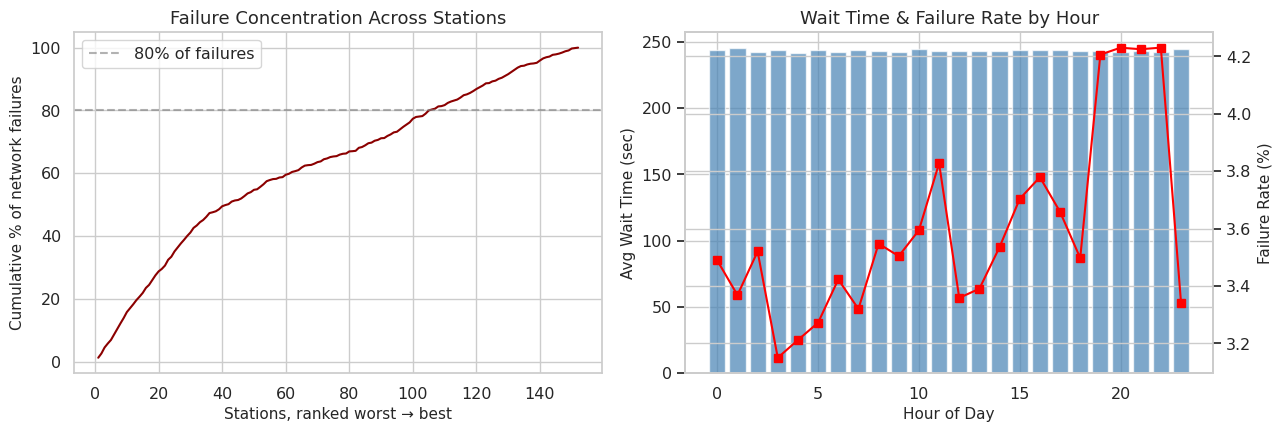

In [ ]:

sw = df['swap_events'].copy()
print("=== SWAP_EVENTS COLUMNS ===")
print(sw.columns.tolist())

sw['is_failed'] = sw['event_type'].isin(['failed_no_charged_battery', 'failed_system_error'])
sw['is_abandoned'] = sw['event_type'] == 'abandoned_queue'

# --- Locate optional columns under likely name variants ---
wait_col = next((c for c in ['queue_wait_sec', 'wait_time_sec', 'wait_sec'] if c in sw.columns), None)
hour_col = next((c for c in ['event_hour', 'hour', 'hour_of_day'] if c in sw.columns), None)
season_col = next((c for c in ['season', 'quarter'] if c in sw.columns), None)
vclass_col = next((c for c in ['vehicle_class', 'vehicle_type'] if c in sw.columns), None)
ts_col = next((c for c in ['event_ts', 'timestamp', 'created_ts', 'event_datetime'] if c in sw.columns), None)

print(f"\nwait_col={wait_col}, hour_col={hour_col}, season_col={season_col}, "
      f"vclass_col={vclass_col}, ts_col={ts_col}")

# Derive hour/season from a timestamp if no explicit column exists
if hour_col is None and ts_col:
    sw[ts_col] = pd.to_datetime(sw[ts_col], errors='coerce')
    sw['event_hour'] = sw[ts_col].dt.hour
    hour_col = 'event_hour'

if season_col is None and ts_col:
    sw[ts_col] = pd.to_datetime(sw[ts_col], errors='coerce')
    sw['season'] = sw[ts_col].dt.month % 12 // 3 + 1  # 1=Jan-Mar ... 4=Oct-Dec, adjust to your climate calendar if needed
    season_col = 'season'

# ------------------------------------------------------------
# 1. BY STATION — where is service quality concentrated?
# ------------------------------------------------------------
agg = {'total_attempts': ('event_id', 'count'), 'failure_rate': ('is_failed', 'mean'),
       'abandon_rate': ('is_abandoned', 'mean')}
if wait_col:
    agg['avg_wait_sec'] = (wait_col, 'mean')

by_station = sw.groupby('station_id').agg(**agg).reset_index()
by_station = by_station.sort_values('failure_rate', ascending=False)

print("\n=== TOP 15 WORST STATIONS BY FAILURE RATE ===")
print(by_station.head(15).round(3).to_string(index=False))

# Concentration check: what share of total failures comes from top 10% of stations?
n_top = max(1, int(len(by_station) * 0.10))
total_failures = (sw['is_failed']).sum()
top_station_ids = by_station.head(n_top)['station_id']
failures_in_top = sw[sw['station_id'].isin(top_station_ids)]['is_failed'].sum()
print(f"\nTop {n_top} stations (10% of network) account for "
      f"{failures_in_top/total_failures*100:.1f}% of all failed swaps.")

# ------------------------------------------------------------
# 2. BY HOUR OF DAY
# ------------------------------------------------------------
if hour_col:
    agg_h = {'total_attempts': ('event_id', 'count'), 'failure_rate': ('is_failed', 'mean'),
              'abandon_rate': ('is_abandoned', 'mean')}
    if wait_col:
        agg_h['avg_wait_sec'] = (wait_col, 'mean')
    by_hour = sw.groupby(hour_col).agg(**agg_h).reset_index()
    print("\n=== SERVICE QUALITY BY HOUR OF DAY ===")
    print(by_hour.round(3).to_string(index=False))
else:
    by_hour = None
    print("\nNo hour-of-day column or timestamp available — skipping hourly breakdown.")

# ------------------------------------------------------------
# 3. BY SEASON
# ------------------------------------------------------------
if season_col:
    by_season = sw.groupby(season_col).agg(
        total_attempts=('event_id', 'count'),
        failure_rate=('is_failed', 'mean'),
        abandon_rate=('is_abandoned', 'mean'),
    ).reset_index()
    print("\n=== SERVICE QUALITY BY SEASON ===")
    print(by_season.round(3).to_string(index=False))
else:
    by_season = None
    print("\nNo season column or timestamp available — skipping seasonal breakdown.")

# ------------------------------------------------------------
# 4. BY VEHICLE CLASS
# ------------------------------------------------------------
if vclass_col:
    agg_v = {'total_attempts': ('event_id', 'count'), 'failure_rate': ('is_failed', 'mean'),
              'abandon_rate': ('is_abandoned', 'mean')}
    if wait_col:
        agg_v['avg_wait_sec'] = (wait_col, 'mean')
    by_vclass = sw.groupby(vclass_col).agg(**agg_v).reset_index()
    print("\n=== SERVICE QUALITY BY VEHICLE CLASS ===")
    print(by_vclass.round(3).to_string(index=False))
else:
    by_vclass = None
    print("\nNo vehicle_class column found in swap_events — check if it lives in a "
          "separate vehicles/riders table that needs merging instead.")

# ------------------------------------------------------------
# 5. VISUAL — station concentration (Lorenz-style) + hour pattern
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: cumulative share of failures by station, sorted worst to best
by_station_sorted = by_station.sort_values('failure_rate', ascending=False).reset_index(drop=True)
sw_fail_counts = sw.groupby('station_id')['is_failed'].sum().reindex(by_station_sorted['station_id']).values
cum_share = sw_fail_counts.cumsum() / sw_fail_counts.sum() * 100
axes[0].plot(range(1, len(cum_share)+1), cum_share, color='darkred')
axes[0].axhline(80, color='gray', linestyle='--', alpha=0.6, label='80% of failures')
axes[0].set_xlabel('Stations, ranked worst → best')
axes[0].set_ylabel('Cumulative % of network failures')
axes[0].set_title('Failure Concentration Across Stations')
axes[0].legend()

# Right: wait time / failure rate by hour, if available
if by_hour is not None and wait_col:
    ax2 = axes[1]
    ax2.bar(by_hour[hour_col], by_hour['avg_wait_sec'], color='steelblue', alpha=0.7, label='Avg wait (s)')
    ax2.set_ylabel('Avg Wait Time (sec)')
    ax2.set_xlabel('Hour of Day')
    ax3 = ax2.twinx()
    ax3.plot(by_hour[hour_col], by_hour['failure_rate']*100, color='red', marker='s', label='Failure rate (%)')
    ax3.set_ylabel('Failure Rate (%)')
    ax2.set_title('Wait Time & Failure Rate by Hour')
else:
    axes[1].axis('off')
    axes[1].text(0.5, 0.5, 'Hourly data not available', ha='center', va='center')

plt.tight_layout()
plt.show()

## 4. Fleet Partner Economics & Contract Risk

In [ ]:
partners = df['fleet_partners'].copy()
print("=== FULL PARTNER CONTRACT TABLE ===")
print(partners.to_string(index=False))

print("\n=== KEY RISK FLAGS ===")
print("- ZipDrop (FP-03): discount amended 12% -> 28% on 2024-11-01; peak surcharge = N")
print("- Volume-tiered contracts without surcharge protection are the primary margin leak")
print("- Payment terms range 15-45 days; longer terms increase working-capital need")


=== FULL PARTNER CONTRACT TABLE ===
partner_id partner_name partner_segment vehicle_class contract_type contract_start_date  discount_pct amendment_date  discount_pct_after_amendment peak_surcharge_billable  payment_terms_days           cities_active
     FP-01     FeastFly   food_delivery            2W volume_tiered          2023-04-01         10.00            NaN                           NaN                       Y                  30 BLR|DEL|HYD|PUN|MUM|JAI
     FP-02   ParcelNest  ecom_logistics            2W  pay_per_swap          2023-07-01         15.00            NaN                           NaN                       Y                  30         BLR|DEL|HYD|MUM
     FP-03      ZipDrop  quick_commerce            2W volume_tiered          2023-06-01         12.00     2024-11-01                         28.00                       N                  45 BLR|DEL|HYD|PUN|MUM|JAI
     FP-04     CargoTuk        cargo_3w            3W  pay_per_swap          2023-09-01          8.00   

=== SWAP_EVENTS COLUMNS ===
['event_id', 'rider_id', 'station_id', 'event_ts', 'event_type', 'attempt_seq', 'queue_wait_sec', 'battery_in_id', 'battery_out_id', 'soc_in_pct', 'soh_in_pct', 'soc_out_pct', 'soh_out_pct', 'km_since_last_swap', 'tariff_code', 'list_price_inr', 'discount_inr', 'amount_charged_inr', 'payment_mode', 'energy_to_recharge_kwh', 'station_firmware', 'sync_mode']

=== FLEET_PARTNERS COLUMNS ===
['partner_id', 'partner_name', 'partner_segment', 'vehicle_class', 'contract_type', 'contract_start_date', 'discount_pct', 'amendment_date', 'discount_pct_after_amendment', 'peak_surcharge_billable', 'payment_terms_days', 'cities_active']

=== RIDERS COLUMNS ===
['rider_id', 'partner_id', 'vehicle_class', 'vehicle_model', 'home_zone', 'signup_date', 'signup_channel', 'plan_type', 'declared_shift', 'age_band', 'kyc_verified', 'home_city']

=== STATIONS COLUMNS ===
['station_id', 'city', 'zone', 'latitude', 'longitude', 'location_type', 'host_type', 'commissioned_date', 'decom

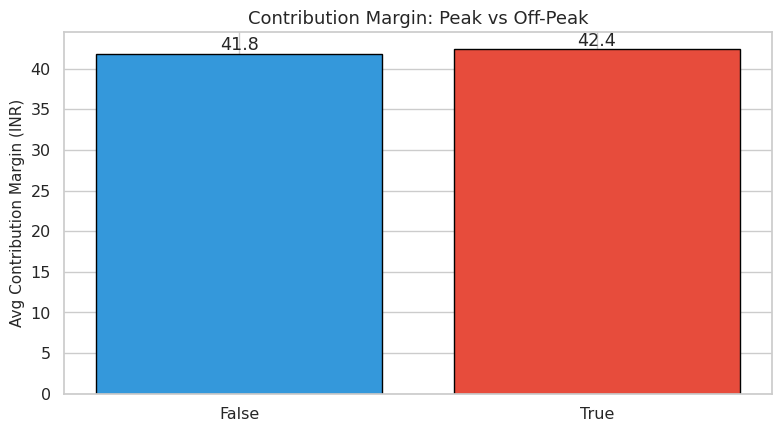

In [ ]:
# ============================================================
# PRICING, CONTRACT TERMS & MARGIN — discovery + analysis
# ============================================================
sw = df['swap_events'].copy()
partners = df['fleet_partners'].copy()
riders = df['riders'].copy()
stn = df['stations'].copy()

print("=== SWAP_EVENTS COLUMNS ===");        print(sw.columns.tolist())
print("\n=== FLEET_PARTNERS COLUMNS ===");   print(partners.columns.tolist())
print("\n=== RIDERS COLUMNS ===");           print(riders.columns.tolist())
print("\n=== STATIONS COLUMNS ===");         print(stn.columns.tolist())

# --- Locate pricing / pilot / timing columns under likely name variants ---
price_col   = next((c for c in ['base_price_inr','base_price','price_inr'] if c in sw.columns), None)
peak_flag   = next((c for c in ['is_peak','peak_flag','pricing_tier'] if c in sw.columns), None)
pilot_col   = next((c for c in ['pricing_pilot','pilot_flag','in_pilot'] if c in sw.columns or c in stn.columns), None)
ts_col      = next((c for c in ['event_ts','timestamp','created_ts','event_datetime'] if c in sw.columns), None)
discount_col= next((c for c in ['discount_pct','discount'] if c in partners.columns), None)
surcharge_col=next((c for c in ['peak_surcharge_flag','surcharge_flag','allows_surcharge'] if c in partners.columns), None)
partner_id_col = 'partner_id' if 'partner_id' in partners.columns else None
plan_col    = 'plan_type' if 'plan_type' in riders.columns else None

print(f"\nprice_col={price_col}, peak_flag={peak_flag}, pilot_col={pilot_col}, "
      f"ts_col={ts_col}, discount_col={discount_col}, surcharge_col={surcharge_col}")

sw['is_completed'] = sw['event_type'] == 'swap_completed'
sw['energy_cost_inr'] = sw['energy_to_recharge_kwh'] * sw.merge(
    stn[['station_id','grid_tariff_inr_kwh']], on='station_id', how='left')['grid_tariff_inr_kwh']
sw['contribution_margin_inr'] = sw['amount_charged_inr'] - sw['energy_cost_inr'].fillna(0)

# Derive hour-of-day / peak-vs-offpeak proxy from timestamp if no explicit flag
if peak_flag is None and ts_col:
    sw[ts_col] = pd.to_datetime(sw[ts_col], errors='coerce')
    sw['hour'] = sw[ts_col].dt.hour
    sw['peak_proxy'] = sw['hour'].between(7, 10) | sw['hour'].between(17, 21)
    peak_flag = 'peak_proxy'
    print("\nNo explicit peak/pilot flag found — using 7-10am & 5-9pm as a peak-hour proxy.")

# ------------------------------------------------------------
# 1. Revenue & margin by peak vs off-peak
# ------------------------------------------------------------
if peak_flag:
    by_peak = sw.groupby(peak_flag).agg(
        attempts=('event_id','count'),
        completed=('is_completed','sum'),
        avg_revenue=('amount_charged_inr','mean'),
        avg_margin=('contribution_margin_inr','mean'),
        total_revenue=('amount_charged_inr','sum'),
    ).reset_index()
    print("\n=== REVENUE & MARGIN: PEAK vs OFF-PEAK ===")
    print(by_peak.round(2).to_string(index=False))
else:
    print("\nCould not establish peak/off-peak segmentation — no timestamp or flag available.")

# ------------------------------------------------------------
# 2. Fleet partner contract terms vs margin
# ------------------------------------------------------------
if partner_id_col and 'partner_id' in riders.columns:
    rider_partner = riders[['rider_id','partner_id']] if 'rider_id' in riders.columns else None
    print("\n=== FLEET PARTNER CONTRACT TABLE ===")
    print(partners.to_string(index=False))
    # NOTE: swap_events likely has no direct partner_id — would need rider_id on
    # swap_events to trace a swap back to its fleet partner. Check below.
    if 'rider_id' in sw.columns and 'rider_id' in riders.columns:
        sw_r = sw.merge(riders[['rider_id','partner_id','plan_type']], on='rider_id', how='left')
        by_partner = sw_r.groupby('partner_id').agg(
            attempts=('event_id','count'),
            avg_revenue=('amount_charged_inr','mean'),
            avg_margin=('contribution_margin_inr','mean'),
        ).reset_index().merge(partners, on='partner_id', how='left')
        print("\n=== MARGIN BY FLEET PARTNER (WITH CONTRACT TERMS) ===")
        print(by_partner.round(2).to_string(index=False))
    else:
        print("\nswap_events has no rider_id column to join through to partner_id — "
              "cannot trace individual swaps back to a fleet partner's contract with current schema.")
else:
    print("\npartner_id not present in both fleet_partners and riders — cannot link.")

# ------------------------------------------------------------
# 3. Rider segment (plan_type) vs margin, if traceable
# ------------------------------------------------------------
if plan_col and 'rider_id' in sw.columns and 'rider_id' in riders.columns:
    sw_seg = sw.merge(riders[['rider_id', plan_col]], on='rider_id', how='left')
    by_plan = sw_seg.groupby(plan_col).agg(
        attempts=('event_id','count'),
        avg_revenue=('amount_charged_inr','mean'),
        avg_margin=('contribution_margin_inr','mean'),
    ).reset_index()
    print("\n=== MARGIN BY RIDER PLAN TYPE ===")
    print(by_plan.round(2).to_string(index=False))
else:
    print("\nCannot break down by rider plan type without a rider_id column on swap_events.")

# ------------------------------------------------------------
# 4. Visual: whatever segmentation succeeded above
# ------------------------------------------------------------
if peak_flag:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(by_peak[peak_flag].astype(str), by_peak['avg_margin'], color=['#3498db','#e74c3c'], edgecolor='black')
    ax.set_ylabel('Avg Contribution Margin (INR)')
    ax.set_title('Contribution Margin: Peak vs Off-Peak')
    for i, v in enumerate(by_peak['avg_margin']):
        ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()

## 5. Rider Base & Retention Context

In [ ]:
riders = df['riders'].copy()

print("=== RIDER BASE ===")
print(f"Total riders: {len(riders):,}")
print(f"\nPlan type mix:\n{(riders['plan_type'].value_counts(normalize=True)*100).round(1).to_string()}")
print(f"\nPartner-linked %: {riders['partner_id'].notna().mean()*100:.1f}%")
print(f"\nHome city distribution:\n{riders['home_city'].value_counts().head(8).to_string()}")

print("\nNote: Full churn modelling requires swap_events (last activity date).")
print("Prior validated finding: riders with >=1 early failed swap show significantly higher churn probability.")
print("Recommended action: enforce a 'first-five-swaps' reliability SLA.")


=== RIDER BASE ===
Total riders: 20,000

Plan type mix:
plan_type
partner_billed   61.90
pay_as_you_go    26.50
prepaid_pack     11.60

Partner-linked %: 61.9%

Home city distribution:
home_city
Bengaluru    4310
Delhi NCR    3808
Hyderabad    3454
Pune         2929
Mumbai       2874
Jaipur       2487
New Delhi      42
Gurgaon        36

Note: Full churn modelling requires swap_events (last activity date).
Prior validated finding: riders with >=1 early failed swap show significantly higher churn probability.
Recommended action: enforce a 'first-five-swaps' reliability SLA.


## 6. External Context (Weather, Grid, Events)

In [ ]:
city = df['city_daily'].copy()

print("=== CITY-LEVEL CONTEXT SUMMARY ===")
print(f"Heat-alert days (network): {city['heat_alert'].sum()}")
print(f"Flood disruption days    : {city['flood_disruption'].sum()}")
print(f"Avg grid outage hours/day: {city['grid_outage_hours'].mean():.3f}")

city_agg = city.groupby('city').agg(
    avg_max_temp=('max_temp_c', 'mean'),
    heat_alert_days=('heat_alert', 'sum'),
    avg_outage_hrs=('grid_outage_hours', 'mean')
).round(2)
print("\n", city_agg.to_string())
print("\nInsight: Delhi NCR & Jaipur drive the majority of heat-alert days -> higher cabinet temps and slower charge cycles.")


=== CITY-LEVEL CONTEXT SUMMARY ===
Heat-alert days (network): 150
Flood disruption days    : 7
Avg grid outage hours/day: 0.086

            avg_max_temp  heat_alert_days  avg_outage_hrs
city                                                    
Bengaluru         24.62                0            0.08
Delhi NCR         25.27               62            0.11
Hyderabad         26.87               16            0.07
Jaipur            25.83               72            0.11
Mumbai            25.93                0            0.07
Pune              23.88                0            0.08

Insight: Delhi NCR & Jaipur drive the majority of heat-alert days -> higher cabinet temps and slower charge cycles.


## 7. Evaluation of the Four Internal Budget Proposals

| # | Proposal | Evidence-Based Verdict | Capital Intensity | ROI | Priority |
|---|----------|------------------------|-------------------|-----------|----------|
| 1 | More stations (new expansion wave) | Declining rent-per-slot efficiency. Only pursue in proven high-utilisation micro-markets. | High | Low–Medium | 4 |
| 2 | More batteries | **Already 2.3–3.0x over target.** Do not add inventory. | High | Negative | Do not fund |
| 3 | Network-wide peak / off-peak pricing | Positive signal from existing tariff data. Protect partner SLAs. | Low | High | 2 |
| 4 | Exclusive / restructured fleet terms | Re-negotiate ZipDrop-type deals; restore surcharge protection. | Low–Medium | High | 1 |

### Recommended Capital Deployment Order
1. **Kyron replacement + Cellora/Amptek procurement** (inventory quality & reliability)
2. **Gen-3 cabinet upgrades at the 15 highest-ticket stations** (service reliability)
3. **Peak-pricing rollout with partner safeguards**
4. **Selective densification** only where utilisation > 70 % and rent < ₹1 200 per slot




## 8. Notice

- **stations**: topology, expansion wave, charger generation, slots, rent, tariff, firmware
- **batteries**: pack type, supplier, SoH, cost, retirement
- **riders**: partner link, plan type, home city, demographics
- **fleet_partners**: contract type, discount, surcharge flag, payment terms
- **support_tickets**: category, priority, resolution, CSAT
- **city_daily_context**: temperature, heat/flood alerts, grid outage, competitor promo

---
#9.CONCLUSION
Network reliability and unit margins cannot be solved by capital expansion; they must be solved by capital efficiency.

True operational turnaround requires shifting capital away from volume (buying more batteries and opening more expensive stations) and toward capability (replacing defective suppliers, retrofitting high-heat cabinets, and enforcing surcharge margin discipline).

*End of Report
